In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier, Pool
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/training_v2.csv")

print("rows:", len(df))
print("columns:", df.shape[1])
print("deaths:", int(df["hospital_death"].sum()))
print("death rate:", round(df["hospital_death"].mean(), 3))

rows: 91713
columns: 186
deaths: 7915
death rate: 0.086


In [2]:
always_survive = (df["hospital_death"] == 0).mean()
print("accuracy if everyone survives:", round(always_survive, 3))

apache = df["apache_4a_hospital_death_prob"]
has_apache = apache >= 0

apache_auc = roc_auc_score(df.loc[has_apache, "hospital_death"], apache[has_apache])
print("APACHE IV AUC, where the score exists:", round(apache_auc, 3))
print("share of rows with an APACHE score:", round(has_apache.mean(), 3))

accuracy if everyone survives: 0.914
APACHE IV AUC, where the score exists: 0.863
share of rows with an APACHE score: 0.887


In [3]:
drop_columns = [
    "encounter_id",
    "patient_id",
    "hospital_id",
    "icu_id",
    "hospital_death",
    "apache_4a_hospital_death_prob",
    "apache_4a_icu_death_prob",
]

cat_columns = [
    "ethnicity",
    "gender",
    "hospital_admit_source",
    "icu_admit_source",
    "icu_stay_type",
    "icu_type",
    "apache_3j_bodysystem",
    "apache_2_bodysystem",
    "apache_2_diagnosis",
    "apache_3j_diagnosis",
]

y = df["hospital_death"].astype(int)
apache_score = df["apache_4a_hospital_death_prob"]
X = df.drop(columns=drop_columns)

for col in cat_columns:
    X[col] = X[col].fillna("missing")
    X[col] = X[col].astype(str)

print("features:", X.shape[1])
print("categorical features:", len(cat_columns))

features: 179
categorical features: 10


In [4]:
X_rest, X_test, y_rest, y_test, apache_rest, apache_test = train_test_split(
    X,
    y,
    apache_score,
    test_size=0.2,
    stratify=y,
    random_state=42,
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_rest,
    y_rest,
    test_size=0.2,
    stratify=y_rest,
    random_state=42,
)

print("train:", len(y_train))
print("valid:", len(y_valid))
print("test:", len(y_test))
print("death rate on the test set:", round(y_test.mean(), 3))

train: 58696
valid: 14674
test: 18343
death rate on the test set: 0.086


In [5]:
model = CatBoostClassifier(
    iterations=400,
    learning_rate=0.08,
    depth=6,
    eval_metric="AUC",
    early_stopping_rounds=40,
    random_seed=42,
    verbose=50,
    allow_writing_files=False,
)

model.fit(
    X_train,
    y_train,
    cat_features=cat_columns,
    eval_set=(X_valid, y_valid),
)

print("stopped at tree", model.best_iteration_, "out of 400")

0:	test: 0.7858066	best: 0.7858066 (0)	total: 136ms	remaining: 54.2s


50:	test: 0.8910035	best: 0.8910035 (50)	total: 3.64s	remaining: 24.9s


100:	test: 0.8993229	best: 0.8993229 (100)	total: 6.53s	remaining: 19.3s


150:	test: 0.9026598	best: 0.9026598 (150)	total: 9.56s	remaining: 15.8s


200:	test: 0.9056384	best: 0.9056384 (200)	total: 12.5s	remaining: 12.4s


250:	test: 0.9064320	best: 0.9064585 (248)	total: 15.5s	remaining: 9.17s


300:	test: 0.9068858	best: 0.9069340 (287)	total: 18.2s	remaining: 6s


350:	test: 0.9071915	best: 0.9073468 (321)	total: 20.8s	remaining: 2.9s


Stopped by overfitting detector  (40 iterations wait)

bestTest = 0.907346761
bestIteration = 321

Shrink model to first 322 iterations.
stopped at tree 321 out of 400


In [6]:
risk = model.predict_proba(X_test)[:, 1]
y_true = y_test.to_numpy()
apache_values = apache_test.to_numpy()

test_auc = roc_auc_score(y_true, risk)
print("test AUC:", round(test_auc, 3))

has_apache = apache_values >= 0
apache_auc = roc_auc_score(y_true[has_apache], apache_values[has_apache])
model_auc_same_rows = roc_auc_score(y_true[has_apache], risk[has_apache])
print("APACHE AUC on the same patients:", round(apache_auc, 3))
print("our AUC on the same patients:", round(model_auc_same_rows, 3))

print()
print("accuracy if everyone survives:", round((y_true == 0).mean(), 3))
print("accuracy at cutoff 0.5:", round(((risk >= 0.5) == y_true).mean(), 3))

deaths = y_true == 1
deaths_found = ((risk >= 0.5) & deaths).sum()
print("deaths found at cutoff 0.5:", int(deaths_found), "out of", int(deaths.sum()))

print("median risk, survivors:", round(float(np.median(risk[~deaths])), 3))
print("median risk, deaths:", round(float(np.median(risk[deaths])), 3))

test AUC: 0.908
APACHE AUC on the same patients: 0.869
our AUC on the same patients: 0.91

accuracy if everyone survives: 0.914
accuracy at cutoff 0.5: 0.934
deaths found at cutoff 0.5: 552 out of 1583
median risk, survivors: 0.02
median risk, deaths: 0.32


In [7]:
predicted = (risk >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()

print("cutoff 0.5")
print("survived, model said survived:", int(tn))
print("survived, model said died:     ", int(fp))
print("died, model said survived:     ", int(fn))
print("died, model said died:         ", int(tp))

cutoff 0.5
survived, model said survived: 16574
survived, model said died:      186
died, model said survived:      1031
died, model said died:          552


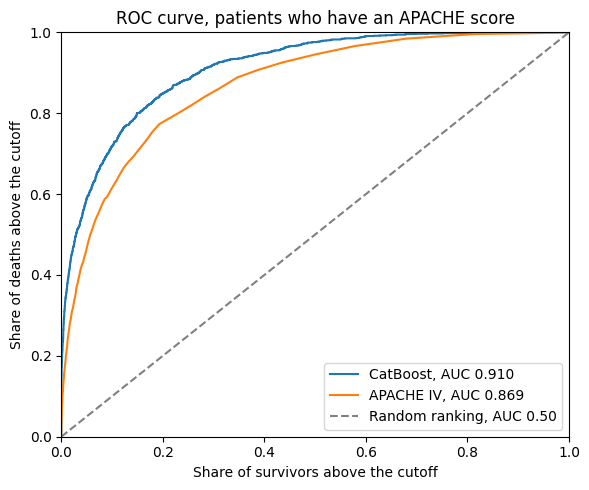

In [8]:
fpr, tpr, _ = roc_curve(y_true[has_apache], risk[has_apache])
fpr_apache, tpr_apache, _ = roc_curve(y_true[has_apache], apache_values[has_apache])

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"CatBoost, AUC {model_auc_same_rows:.3f}")
plt.plot(fpr_apache, tpr_apache, label=f"APACHE IV, AUC {apache_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random ranking, AUC 0.50")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.xlabel("Share of survivors above the cutoff")
plt.ylabel("Share of deaths above the cutoff")
plt.title("ROC curve, patients who have an APACHE score")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [9]:
died_rows = np.where(y_true == 1)[0]
typical_death_risk = np.median(risk[died_rows])
row = died_rows[np.argmin(np.abs(risk[died_rows] - typical_death_risk))]

patient = X_test.iloc[[row]]
patient_risk = float(risk[row])

print("died:", int(y_true[row]))
print("model risk:", round(patient_risk, 3))
print("typical death risk:", round(float(typical_death_risk), 3))

died: 1
model risk: 0.32
typical death risk: 0.32


In [10]:
shap_row = model.get_feature_importance(
    Pool(patient, cat_features=cat_columns),
    type="ShapValues",
)[0]

start_score = shap_row[-1]
pushes = shap_row[:-1]

explain = pd.DataFrame({
    "feature": list(patient.columns),
    "value": patient.iloc[0].to_numpy(),
    "push": pushes,
})
explain["size"] = explain["push"].abs()
explain = explain.sort_values("size", ascending=False)

print("starting score:", round(float(start_score), 3))
print("sum of pushes:", round(float(pushes.sum()), 3))
print()
print(explain.head(10).drop(columns="size").to_string(index=False))

starting score: -3.446
sum of pushes: 2.694

           feature     value     push
               age      85.0 0.522936
  d1_heartrate_max     177.0 0.424106
      d1_sysbp_min      70.0 0.239306
  gcs_motor_apache       4.0 0.230188
  pre_icu_los_days  2.195833 0.134528
   gcs_eyes_apache       2.0 0.125244
  icu_admit_source     Floor 0.120320
       d1_spo2_min      87.0 0.119688
 gcs_verbal_apache       2.0 0.113646
apache_2_diagnosis     110.0 0.111355


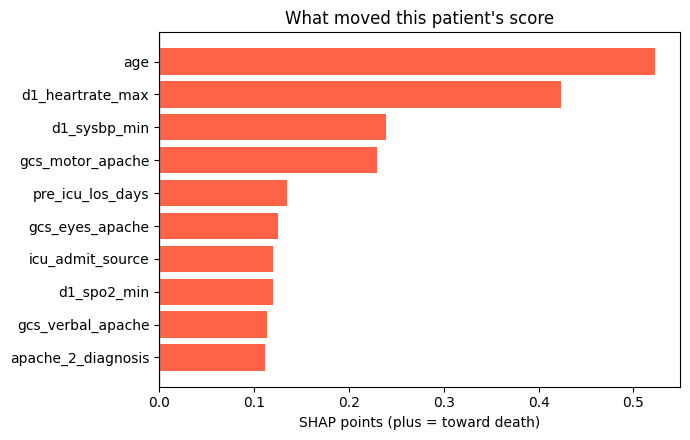

In [11]:
top = explain.head(10).iloc[::-1]
colors = ["tomato" if push > 0 else "steelblue" for push in top["push"]]

plt.figure(figsize=(7, 4.5))
plt.barh(top["feature"], top["push"], color=colors)
plt.axvline(0, color="gray", linewidth=1)
plt.xlabel("SHAP points (plus = toward death)")
plt.title("What moved this patient's score")
plt.tight_layout()
plt.show()